**Unit 11 · Notebook 01**

# Transform a copy without losing cases

**Learning objective:** Evaluate a recoded table against the supplied case records.

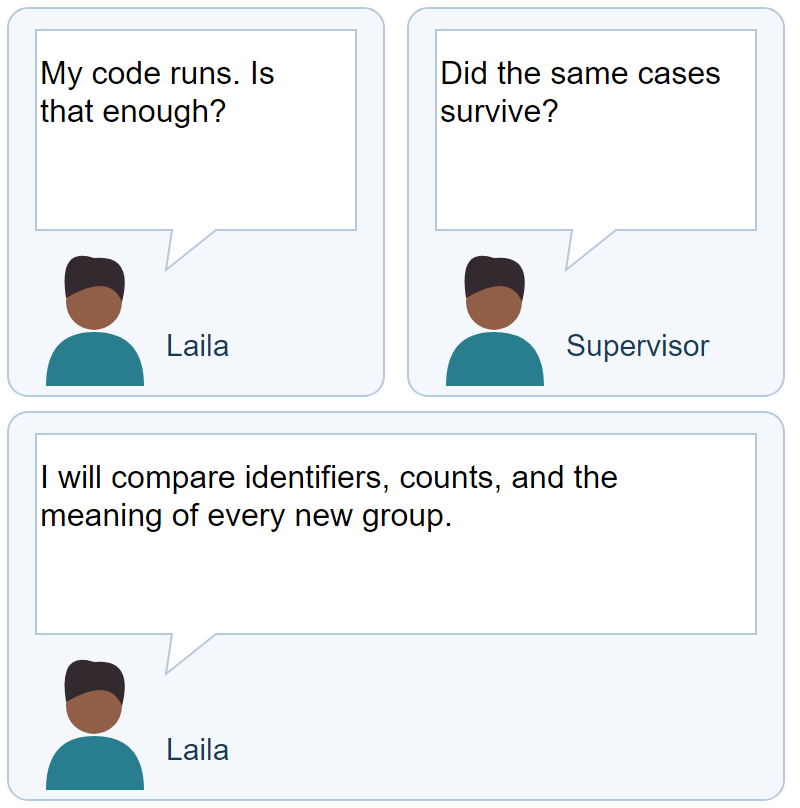

All records in this exercise are invented.

## Group the supplied cases by age

Laila needs to separate cases younger than five years from cases aged five years
or older. The invented case records for this task are provided here:

| Case identifier | District | Onset date | Age (completed years) | Sex |
| --- | --- | --- | --- | --- |
| C01 | Kambia | 2021-10-18 | 8 | F |
| C02 | Kambia | 2021-10-19 | 12 | M |
| C03 | Kambia | 2021-10-20 | 4 | F |
| C04 | Port Loko | 2021-10-20 | 17 | M |

Age is recorded in completed years. Add an age group to each case using these rules:

- `under5`: age is less than 5.
- `5plus`: age is 5 or older.
- `unknown`: age is missing. Keep the case in the table.

The age-group definitions are fixed for this report. An eight-year-old belongs
in `5plus`. A case aged exactly five years also belongs in `5plus`.

1. Run the visible worked example below. It shows the groups for ages 4, 5, 8,
   and a missing age. These examples explain the rule; they are not additional cases.
2. Inspect the four supplied case records. Decide which group C01 belongs to,
   how many cases are younger than five, and how many rows should remain after
   adding the age groups. Also choose what should happen if an age is missing.
3. Run the controls cell after the worked example and enter your answers.
4. Select **Submit**. The notebook creates and displays a recoded copy using
   the fixed definitions above, then gives feedback on your answers.
5. Compare the recoded table with the supplied records. Check that every case
   identifier is still present and appears the same number of times. Matching
   row counts alone would not show whether one case had been replaced by another.

The supplied records stay unchanged. Your answers are predictions and review
judgments; they do not change the age-group definitions or remove cases.


![Course dictionary example; use field meaning when recoding](../../readings/ucsf/assets/slide-previews/unit-2-056.jpg)

*Course dictionary example; use field meaning when recoding.*


## Apply the fixed age groups

Select the code cell below and press **Shift+Enter**. Compare the groups for a four-year-old, a five-year-old, an eight-year-old, and a missing age. This worked example is unscored and runs without the setup cell.

Then use the controls cell that follows to answer the review questions about the four supplied cases.

In [ ]:
# Run this worked example: apply the fixed age groups.
def age_group(age):
    """Fixed categories for this report; the fifth birthday starts 5plus."""
    if age is None:
        return 'unknown'
    return 'under5' if age < 5 else '5plus'

# Boundary and missing-age examples, separate from the four case records.
example_ages = [4, 5, 8, None]
for example_age in example_ages:
    example_label = "Missing" if example_age is None else example_age
    print(f"Age {example_label}: {age_group(example_age)}")


In [ ]:
# Run once to inspect the data and display the controls.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display
from html import escape
from collections import Counter
from datetime import date
import traitlets

class CourseChoices(widgets.VBox):
    value = traitlets.Tuple(default_value=())
    disabled = traitlets.Bool(False)
    def __init__(self, label, options):
        self.options = options
        self.boxes = [widgets.Checkbox(description=text, value=False, indent=False, layout=widgets.Layout(width="100%", height="auto")) for text, value in options]
        super().__init__([widgets.HTML("<b>" + escape(label) + "</b>"), *self.boxes], layout=widgets.Layout(width="100%"))
        for box in self.boxes:
            box.observe(self.collect, names="value")
        self.observe(self.lock, names="disabled")
    def collect(self, change):
        self.value = tuple(value for box, (text, value) in zip(self.boxes, self.options) if box.value)
    def lock(self, change):
        for box in self.boxes:
            box.disabled = self.disabled

def control_answer(control):
    if isinstance(control, CourseChoices):
        return list(control.value)
    if getattr(control, "course_integer", False):
        text = control.value.strip()
        return int(text) if text.isascii() and text.isdigit() else None
    return control.value

display(widgets.HTML("""<style>
.course-task-control { height: auto !important; margin-bottom: 0.75rem; gap: 0.25rem; }
.course-task-control .widget-checkbox { height: auto !important; min-height: 2rem; }
.course-task-control .widget-checkbox label { white-space: normal !important; height: auto !important; overflow: visible !important; text-overflow: clip !important; line-height: 1.5; align-items: flex-start; }
.course-task-control .widget-checkbox input { flex-shrink: 0; margin-top: 0.3rem; }
.course-task-control > label { width: auto !important; text-align: left; white-space: normal; line-height: 1.4; }
.course-task-control > select, .course-task-control > input { width: 100% !important; min-width: 0; max-width: 100%; flex: 0 0 auto !important; }
</style>"""))

training_data = {'cases': [{'case_id': 'C01', 'district': 'Kambia', 'onset_date': '2021-10-18', 'age': 8, 'sex': 'F'}, {'case_id': 'C02', 'district': 'Kambia', 'onset_date': '2021-10-19', 'age': 12, 'sex': 'M'}, {'case_id': 'C03', 'district': 'Kambia', 'onset_date': '2021-10-20', 'age': 4, 'sex': 'F'}, {'case_id': 'C04', 'district': 'Port Loko', 'onset_date': '2021-10-20', 'age': 17, 'sex': 'M'}], 'lab': [{'case_id': 'C01', 'code': 'P'}, {'case_id': 'C02', 'code': 'PEND'}, {'case_id': 'C02', 'code': 'NEG'}, {'case_id': 'C99', 'code': 'X'}], 'code_map': {'P': 'positive', 'NEG': 'negative', 'PEND': 'pending'}, 'dictionary': [{'field': 'case_id', 'type': 'text', 'required': True, 'meaning': 'Stable case event identifier; preserve leading zeros'}, {'field': 'district', 'type': 'controlled text', 'required': True, 'meaning': 'Reporting district: Kambia or Port Loko'}, {'field': 'onset_date', 'type': 'ISO date', 'required': True, 'meaning': 'First symptom date; not specimen date'}, {'field': 'age', 'type': 'integer years', 'required': True, 'meaning': 'Completed years, 0 to 120'}], 'flows': [{'step': 1, 'location': 'Collection', 'output': 'Case event'}, {'step': 2, 'location': 'District database', 'output': 'Stored case_id'}, {'step': 3, 'location': 'Authorized analyst view', 'output': 'Scoped extract'}, {'step': 4, 'location': 'District summary', 'output': 'Aggregates for the briefing'}], 'age_cutoff': 5, 'draft_counts': {'district': 'Kambia', 'numerator': 3, 'denominator': 4}, 'population': None, 'causal_comparison': None, 'draft': [{'claim': 'counts', 'text': 'Three of four reported cases are from Kambia.'}, {'claim': 'risk', 'text': 'Kambia residents have three times the disease risk of Port Loko residents.'}, {'claim': 'cause', 'text': 'The reporting system caused the difference between districts.'}, {'claim': 'followup', 'text': 'Resolve the conflicting laboratory records before reporting final laboratory status.'}]}

def show_table(rows):
    if not rows:
        display(widgets.HTML("<p>No rows selected.</p>"))
        return
    names = list(rows[0])
    header = "".join("<th>" + escape(str(name)) + "</th>" for name in names)
    body = "".join("<tr>" + "".join("<td>" + escape(str(row.get(name, ""))) + "</td>" for name in names) + "</tr>" for row in rows)
    display(widgets.HTML('<div style="overflow-x:auto"><table><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table></div>'))


def summarize(data):
    rows=data['cases']
    return {'district':dict(Counter(r['district'] for r in rows)),
            'onset':dict(sorted(Counter(r['onset_date'] for r in rows).items())),
            'age_group':dict(Counter('under5' if r['age']<data['age_cutoff'] else '5plus' for r in rows)),
            'sex':dict(Counter(r['sex'] for r in rows))}


def supported_claims(data):
    draft=data['draft_counts']
    counts=summarize(data)['district']
    lab_counts=Counter(r['case_id'] for r in data['lab'])
    supports={
        'counts': counts.get(draft['district'],0)==draft['numerator'] and len(data['cases'])==draft['denominator'],
        'risk': False,  # No population risk claim can follow from a report share alone.
        'cause': False, # No causal claim can follow from this descriptive case extract.
        'followup': any(v>1 for v in lab_counts.values())
    }
    return sorted(key for key,value in supports.items() if value)


def age_group(age):
    """Fixed categories for this report; the fifth birthday starts 5plus."""
    if age is None:
        return 'unknown'
    return 'under5' if age < 5 else '5plus'


def expected_answers(unit,data):
    if unit==9: return {'id_type':'text','pending':data['code_map']['PEND'],'unknown':'flag'}
    if unit==10: return {'key':'case_id','relationship':'one_many','flow':'collect_store_view_summary'}
    if unit==11: return {'case_group':age_group(data['cases'][0]['age']),'under5':sum(age_group(r['age'])=='under5' for r in data['cases']),'rows':len(data['cases']),'missing':'retain_unknown'}
    if unit==12:
        counts=Counter(r['case_id'] for r in data['lab'])
        return {'join':'left','conflicts':sum(v>1 for v in counts.values()),'unknown':'quarantine'}
    if unit==13:
        groups=summarize(data)['district']
        return {'kambia':groups.get('Kambia',0),'denominator':'reported_cases','chart':'onset','rate':'unavailable'}
    if unit==14:
        return {'supported':supported_claims(data),
                'risk':'needs_population','release':'human_review'}
    raise ValueError(unit)


def evaluate_answer(unit, response, data):
    expected = expected_answers(unit, data)
    if not isinstance(response, dict) or any(response.get(k) is None or response.get(k) == [] for k in expected):
        return "incomplete"
    for key, value in expected.items():
        actual = response.get(key)
        if isinstance(value, list):
            if not isinstance(actual, (list, tuple)) or sorted(actual) != sorted(value):
                return "incorrect"
        elif type(actual) is not type(value) or actual != value:
            return "incorrect"
    return "correct"


def build_artifact(unit,response,data):
    """Return inspectable outputs; leave original records untouched."""
    if unit==9:
        mapped=[{'source_code':r['code'],'value':data['code_map'].get(r['code']),
                 'action':'mapped' if r['code'] in data['code_map'] else ('review required' if response['unknown']=='flag' else 'UNSAFE: discarded unknown code')}
                for r in data['lab']]
        return {'Field dictionary':data['dictionary'],'Value reconciliation':mapped}
    if unit==10:
        keys=Counter(r[response['key']] for r in data['cases'])
        return {'Key audit':[{'candidate':response['key'],'distinct':len(keys),'rows':len(data['cases']),
                              'unique':all(v==1 for v in keys.values())}],
                'Record flow':data['flows'] if response['flow']=='collect_store_view_summary' else list(reversed(data['flows']))}
    if unit==11:
        output=[]
        for row in data['cases']:
            copy=dict(row)
            copy['age_group']=age_group(row['age'])
            output.append(copy)
        before=Counter(r['case_id'] for r in data['cases']);after=Counter(r['case_id'] for r in output)
        return {'Transformed copy':output,'Reconciliation':[{'input_rows':len(data['cases']),'output_rows':len(output),
                  'same_ID_multiplicity':before==after,'under5':sum(r['age_group']=='under5' for r in output)}]}
    if unit==12:
        index={}
        for row in data['lab']: index.setdefault(row['case_id'],[]).append(row)
        linked=[];review=[]
        for row in data['cases']:
            matches=index.get(row['case_id'],[])
            if not matches and response['join']=='inner': continue
            code=matches[0]['code'] if len(matches)==1 else None
            status='conflict' if len(matches)>1 else ('unmatched' if not matches else data['code_map'].get(code,'unmapped'))
            linked.append({**row,'result':status})
        case_ids={r['case_id'] for r in data['cases']}
        for row in data['lab']:
            errors=[]
            if row['case_id'] not in case_ids: errors.append('unknown case identifier')
            if len(index[row['case_id']])>1: errors.append('conflicting results; verify source')
            if row['code'] not in data['code_map']: errors.append('unmapped result code')
            review.append({**row,'accepted':not errors,'review':'; '.join(errors)})
        # Only resolved, mapped records enter the candidate exchange table. No network POST.
        payload=[{'case_id':r['case_id'],'result':data['code_map'][r['code']],'source':'training-lab'}
                 for r in data['lab'] if len(index[r['case_id']])==1 and r['case_id'] in case_ids and r['code'] in data['code_map']]
        return {'Linked case view':linked,'Import validation':review,'Candidate exchange rows':payload}
    if unit==13:
        summary=summarize(data);total=len(data['cases'])
        table=[{'district':k,'reported_cases':v,'share_of_reports':round(v/total,3) if total else None,'population_rate':'unavailable: no population denominator'} for k,v in summary['district'].items()]
        return {'District briefing':table,'Person summary':[{'dimension':kind,'category':k,'count':v} for kind in ['age_group','sex'] for k,v in summary[kind].items()],
                'Time summary':[{'onset_date':k,'cases':v} for k,v in summary['onset'].items()]}
    if unit==14:
        total=len(data['cases']);counts=summarize(data)['district']
        return {'Draft review':[{'claim':r['text'],'your_decision':'supported' if r['claim'] in response['supported'] else 'not supported'} for r in data['draft']],
                'Evidence for the briefing':[{'measure':'Reported cases','value':total},
                     {'measure':'Kambia share of reports','value':counts.get('Kambia',0)/total if total else None},
                     {'measure':'Population denominator','value':'Not supplied'},
                     {'measure':'Causal comparison','value':'Not supplied'}]}
    raise ValueError(unit)

unit11_response = None
controls = {}
display(widgets.HTML('<p>Enter a whole number of zero or more. Leave a field blank if you have not answered it yet.</p>'))
show_table(training_data['cases'])
controls['case_group'] = widgets.Dropdown(description='Age group for case C01', options=[('Select an answer', None), ('Under 5 years', 'under5'), ('5 years or older', '5plus'), ('Unknown age', 'unknown')], value=None, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['case_group'].add_class('course-task-control')
display(controls['case_group'])
controls['under5'] = widgets.Text(description='Number of cases younger than 5', value='', placeholder='Enter a whole number', style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['under5'].course_integer = True
controls['under5'].add_class('course-task-control')
display(controls['under5'])
controls['rows'] = widgets.Text(description='Rows after adding age groups', value='', placeholder='Enter a whole number', style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['rows'].course_integer = True
controls['rows'].add_class('course-task-control')
display(controls['rows'])
controls['missing'] = widgets.Dropdown(description='If a case has no recorded age', options=[('Select an answer', None), ('Retain case with unknown age group', 'retain_unknown'), ('Drop the case', 'drop')], value=None, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['missing'].add_class('course-task-control')
display(controls['missing'])


## Submit your decision

Run the next cell to display **Submit**, then select the button for feedback. Only an explicit submission records an attempt. Revise your choices and submit again to retry.

In [ ]:
# Run once to display Submit. Running this cell does not submit an attempt.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display, clear_output
from comm import create_comm
from html import escape

def _show_course_submission():
    prepare = '\nunit11_response = {key: control_answer(control) for key, control in controls.items()}\nexpected = expected_answers(11, training_data)\nlabels = {\'case_group\': \'Age group for case C01\', \'under5\': \'Number of cases younger than 5\', \'rows\': \'Rows after adding age groups\', \'missing\': \'If a case has no recorded age\'}\noption_labels = {\'case_group\': {\'under5\': \'Under 5 years\', \'5plus\': \'5 years or older\', \'unknown\': \'Unknown age\'}, \'under5\': {}, \'rows\': {}, \'missing\': {\'retain_unknown\': \'Retain case with unknown age group\', \'drop\': \'Drop the case\'}}\nevidence = {\'case_group\': \'Compare the age of C01 with the fixed five-year boundary.\', \'under5\': \'Count supplied cases with age strictly below five.\', \'rows\': \'Adding an age-group column should preserve every case row.\', \'missing\': \'An unknown age does not remove a case.\'}\nfeedback_rows = []\nfor key, target in expected.items():\n    actual = unit11_response.get(key)\n    unanswered = actual is None or actual == []\n    correct = (sorted(actual) == sorted(target) if isinstance(target, list) and isinstance(actual, list) else actual == target)\n    shown = \', \'.join(option_labels[key].get(value, str(value)) for value in actual) if isinstance(actual, list) else option_labels[key].get(actual, str(actual))\n    feedback_rows.append({"Question": labels[key], "Submitted": ("Enter a whole number of zero or more" if getattr(controls[key], "course_integer", False) else "No choice selected") if unanswered else shown,\n                          "Feedback": "Answer needed" if unanswered else "Meets the stated rule" if correct else "Revise this decision",\n                          "Evidence to inspect": evidence[key]})\nshow_table(feedback_rows)\nresult = evaluate_answer(11, unit11_response, training_data)\nif result == "incomplete":\n    print("Complete every field before submitting again.")\nelse:\n    artifact = build_artifact(11, unit11_response, training_data)\n    if isinstance(artifact, dict):\n        for title, rows in artifact.items():\n            print(title)\n            show_table(rows)\n    else:\n        show_table(artifact)\n'
    fields = ()
    controls_for_task = dict(globals().get("controls", {}))
    submit = widgets.Button(description="Submit", button_style="info", disabled=True)
    feedback = widgets.HTML(value="Connecting to your learning record...")
    artifact_output = widgets.Output(layout=widgets.Layout(width="100%"))
    channel = create_comm(target_name="al.submit", data={"cell": '2'})
    def status(text):
        feedback.value = '<div role="status" aria-live="polite">' + text + '</div>'
    def receive(message):
        data = message["content"]["data"]
        if data.get("ready"):
            status("When your answer is ready, select Submit for feedback.")
        elif data.get("outcome") == "Incomplete":
            status("<b>Not complete yet.</b> Answer every part, then submit again. This attempt was recorded.")
        elif data.get("outcome") == "Correct":
            status("<b>Correct.</b> Your submitted answer follows the stated data and rules. This attempt was recorded.")
        elif data.get("outcome") == "Incorrect":
            status("<b>Not yet correct.</b> Compare your submitted answer with the displayed data and rules. Revise and submit again. This attempt was recorded.")
        else:
            status(escape(data.get("error", "Could not record this attempt. Please submit again.")))
        for control in controls_for_task.values():
            control.disabled = False
        submit.disabled = False
    channel.on_msg(receive)
    def send(_):
        if submit.disabled:
            return
        submit.disabled = True
        for control in controls_for_task.values():
            control.disabled = True
        status("Checking and recording your submitted answer...")
        try:
            with artifact_output:
                clear_output(wait=True)
                exec(prepare, globals())
                if fields:
                    rows = ''.join('<tr><th style="text-align:left">' + escape(name) + '</th><td>' +
                                   escape(str(globals().get(name))) + '</td></tr>' for name in fields)
                    display(widgets.HTML('<b>Submitted answer</b><table>' + rows + '</table>'))
            channel.send({"submit": True})
        except Exception as error:
            status("Could not prepare your answer: " + escape(str(error)) + ". Run the required cells and try again. No attempt was submitted.")
            for control in controls_for_task.values():
                control.disabled = False
            submit.disabled = False
    def edited(_):
        if not submit.disabled:
            status("Changes not submitted. Select Submit for feedback.")
    for control in controls_for_task.values():
        control.observe(edited, names="value")
    submit.on_click(send)
    display(submit, artifact_output, feedback)

_show_course_submission()


## Reflect on the decision

Run the next cell. Write your reflections, then select **Record** to save them with your learner record in this browser. Reflections are unscored.

In [ ]:
# Run this cell to write and record your reflections.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from html import escape
from IPython.display import display
from comm import create_comm

def _reflection_section(section, questions):
    prompts = [question["prompt"] for question in questions]
    fields = []
    for number, prompt in enumerate(prompts, 1):
        field = widgets.Textarea(placeholder="Write your reflection here", rows=5,
                                 layout=widgets.Layout(width="100%"))
        fields.append(field)
        display(widgets.VBox([
            widgets.HTML(value=f"<strong>{number}. {escape(prompt)}</strong>"), field
        ], layout=widgets.Layout(width="100%", padding="0.5rem", margin="0 0 0.5rem 0")))
    button = widgets.Button(description="Record", button_style="info", disabled=True)
    status = widgets.HTML(value="Connecting to your browser learner record...")
    status.add_class("course-reflection-status")
    channel = create_comm(target_name="al.reflections", data={"section": section})
    def receive(message):
        data = message["content"]["data"]
        if "entries" in data:
            entries = data["entries"]
            restored = 0
            earlier = 0
            for question, field in zip(questions, fields):
                saved = next((entry for entry in reversed(entries) if
                    (entry.get("id") == question["id"] and entry.get("version") == question["version"]) or
                    (question["version"] == 1 and not entry.get("id") and entry["prompt"] in question["legacyPrompts"])), None)
                field.value = saved["answer"] if saved else ""
                restored += saved is not None
                earlier += any(entry.get("id") == question["id"] and entry.get("version") != question["version"] for entry in entries)
            status.value = "Recorded reflections restored." if restored else "Select Record to save in this browser."
            if earlier or any(entry.get("history") for entry in entries) or len(entries) > restored:
                status.value += " Earlier responses remain in My learning record and Download reflections. Review them before answering revised questions."
        elif data.get("saved"):
            status.value = "Recorded in this browser. Your reflections are unscored."
        else:
            status.value = escape(data.get("error", "Could not record. Please try again."))
        button.disabled = False
    channel.on_msg(receive)
    def record(_):
        button.disabled = True
        status.value = "Recording..."
        channel.send({"entries": [{**question, "answer": field.value}
                                  for question, field in zip(questions, fields)]})
    def edited(_):
        status.value = "Changes not recorded. Select Record to save."
    for field in fields:
        field.observe(edited, names="value")
    button.on_click(record)
    display(button, status)

_reflection_section('exercise:u11-recode-reconcile', [{'id': 'q1', 'version': 1, 'prompt': 'What additional checks would detect a case replaced by another case?', 'legacyPrompts': ['What additional checks would detect a case replaced by another case?']}, {'id': 'q2', 'version': 1, 'prompt': 'How would you record a change to the age-group definition?', 'legacyPrompts': ['How would you record a change to the age-group definition?']}])


## Continue learning

[Next notebook](u12-n01-link-exchange.ipynb) · [Course start](u00-n00-start-here.ipynb)

Review attempts, hints, and recommendations in the **Learning** panel.

## References

- Public Health Informatics for FETP, Version 2 Unit 5 transformation/preparation sections; UCSF Unit 11 topic wrapper and Unit 5 cleaning assignment.
- [Unit 2 course slides (local PDF)](../../readings/ucsf/assets/unit-2-version-2-slides.pdf).
